# **Logistic Regression baseline for Salama**

We want to compare our DistilBERT models against Logistic Regression to demonstrate whether transformer-based models actually improves GBV classification as compared with a traditional machine-learning approach.

In [1]:
# Importing the necessary libraries
import pandas as pd
import numpy as np

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [5]:
# Loading the datasets
train_gbv = pd.read_csv("../../data/train_consensus.csv")
dev_gbv = pd.read_csv("../../data/development.csv")


In [6]:
train_gbv.shape

(4181, 3)

In [7]:
dev_gbv.shape

(420, 3)

In [9]:
train_gbv.columns

Index(['question_id', 'question_text', 'final_labels'], dtype='str')

In [10]:
dev_gbv.columns

Index(['question_id', 'question_text', 'final_labels'], dtype='str')

Confirming which columns contain the narratives and GBV labels.

In [11]:
# Preview the training dataset
display(train_gbv.head(3))

# Preview the development dataset
display(dev_gbv.head(3))

,question_id,question_text,final_labels
0,Question 1,Title: Workplace Sexual Harassment while WFH\n...,no_crisis
1,Question 2,Title: I’m scared\n\nText: I don’t know what t...,domesticviolence_ongoing
2,Question 3,Title: Is my supervisor harassing me?\n\nText:...,sexualharassment_ongoing


,question_id,question_text,final_labels
0,Question 1,Title: I miss him like crazy.\n\nText: In earl...,domesticviolence_past
1,Question 2,Title: Victims and tenant/landlord issues\n\nT...,domesticviolence_past
2,Question 3,Title: I was witness to what I think was domes...,No crisis


Inspecting the labels on both datasets to reproduce the same binary classification setup used during DistilBERT training.

In [14]:
print("Training labels:")
print(train_gbv["final_labels"].value_counts(dropna=False))

print("\nDevelopment labels:")
print(dev_gbv["final_labels"].value_counts(dropna=False))

Training labels:
final_labels
no_crisis                                                                         1160
selfharm_ongoing                                                                   558
suicideideation_passive_ongoing                                                    438
suicideideation_active_ongoing                                                     365
domesticviolence_past                                                              230
                                                                                  ... 
domesticviolence_ongoing, rape_past                                                  1
sexualharassment_past, rape_past                                                     1
sexualharassment_ongoing, sexualharassment_past                                      1
suicideideation_active_ongoing, childabuse_endangerment_past, selfharm_ongoing       1
suicideideation_active_past, suicideideation_active_ongoing                          1
Name: count, 

There are differences in some labels: Training dataset uses `no_crisis` while development uses `No crisis`.

There's also: `childabuse_endangerment` in the training dataset while development uses `childabuseendangerment`

**Standardizing the column names**

In [15]:
train_gbv.columns = train_gbv.columns.str.strip().str.lower()
dev_gbv.columns = dev_gbv.columns.str.strip().str.lower()

print("Training columns:", train_gbv.columns.tolist())
print("Development columns:", dev_gbv.columns.tolist())

Training columns: ['question_id', 'question_text', 'final_labels']
Development columns: ['question_id', 'question_text', 'final_labels']


**Inspecting narratives for annotations**

In [17]:
print("TRAINING NARRATIVE")
print(train_gbv["question_text"].iloc[1])

print("\n" + "=" * 70 + "\n")

print("DEVELOPMENT NARRATIVE")
print(dev_gbv["question_text"].iloc[0])

TRAINING NARRATIVE
Title: I’m scared

Text: I don’t know what to do anymore. I am terrified. I got a beer bottle broken in my face tonight. He then took our one year old daughter and locked himself in the room with her. I’m a recovering addict (3years sober) but he continues to use my past against me.. my family adores him! We don’t have many resources where I live, but even with resources.. I don’t want to leave him. I feel like I’m the “bad guy” somehow. I’m a stay at home mom and I’m afraid if I call the cops, they’ll just take my daughter since I don’t have an income! He insists that I don’t work, he wants me home with our daughter. But it’s been getting worse and worse. Idk what to do. I’m literally afraid for my life if I try to leave. I just need some advice! Please!!

For any crisis present, mark whether it is Ongoing or Past. 
**Leave a row blank if that crisis type is not present.**


DEVELOPMENT NARRATIVE
Title: I miss him like crazy.

Text: In early May, my (now) ex-boyfrie

In [ ]:
# Checking how many narratives have the annotation
annotation = r"leave a row blank if that crisis type is not present"

print(
    "Training:",
    train_gbv["question_text"].str.contains(
        annotation, case=False, na=False, regex=True
    ).sum()
)

print(
    "Development:",
    dev_gbv["question_text"].str.contains(
        annotation, case=False, na=False, regex=True
    ).sum()
)

Training: 4181
Development: 420


In [ ]:
# Removing the annotation instruction
import re

annotation_pattern = (
    r"(?i)leave\s+a\s+row\s+blank\s+"
    r"if\s+that\s+crisis\s+type\s+is\s+not\s+present"
)

for df in [train_gbv, dev_gbv]:
    df["question_text"] = (
        df["question_text"]
        .str.replace(annotation_pattern, "", regex=True)
        .str.strip()
    )

# Confirm removal
print(
    "Training remaining:",
    train_gbv["question_text"].str.contains(
        annotation_pattern, na=False, regex=True
    ).sum()
)

print(
    "Development remaining:",
    dev_gbv["question_text"].str.contains(
        annotation_pattern, na=False, regex=True
    ).sum()
)

Training remaining: 0
Development remaining: 0


In [20]:
# Confirming whether any annotation text remains
# Inspect the end of the cleaned narratives
print("TRAINING NARRATIVE END:")
print(repr(train_gbv["question_text"].iloc[1][-600:]))

print("\nDEVELOPMENT NARRATIVE END:")
print(repr(dev_gbv["question_text"].iloc[0][-600:]))

TRAINING NARRATIVE END:
'ober) but he continues to use my past against me.. my family adores him! We don’t have many resources where I live, but even with resources.. I don’t want to leave him. I feel like I’m the “bad guy” somehow. I’m a stay at home mom and I’m afraid if I call the cops, they’ll just take my daughter since I don’t have an income! He insists that I don’t work, he wants me home with our daughter. But it’s been getting worse and worse. Idk what to do. I’m literally afraid for my life if I try to leave. I just need some advice! Please!!\n\nFor any crisis present, mark whether it is Ongoing or Past. \n**.**'

DEVELOPMENT NARRATIVE END:
"my future again, and am looking forward to the next step. There is no worry on my end that I'll get back together with him but I guess I'm still grieving the life we had and the future we planned. Hopefully, I will never see or speak to him ever again because it's what's best for me. I just miss him so damn much. I wish things could have b

In [21]:
# Remove remaining annotation instructions and formatting
annotation_pattern = (
    r"(?i)For any crisis present,\s*"
    r"mark whether it is Ongoing or Past\.\s*"
    r"\*\*\.\*\*"
)

for df in [train_gbv, dev_gbv]:
    df["question_text"] = (
        df["question_text"]
        .str.replace(annotation_pattern, "", regex=True)
        .str.strip()
    )

# Verify cleaning
print("TRAINING NARRATIVE END:")
print(repr(train_gbv["question_text"].iloc[1][-250:]))

print("\nDEVELOPMENT NARRATIVE END:")
print(repr(dev_gbv["question_text"].iloc[0][-250:]))

TRAINING NARRATIVE END:
'e my daughter since I don’t have an income! He insists that I don’t work, he wants me home with our daughter. But it’s been getting worse and worse. Idk what to do. I’m literally afraid for my life if I try to leave. I just need some advice! Please!!'

DEVELOPMENT NARRATIVE END:
"e. I just miss him so damn much. I wish things could have been different. I wish I could have told him that I loved him one last time. I wish it wasn't this hard. \n\nAnyway, I've just been missing him and needed to vent a little. Thanks for listening."


In [22]:
# Standardizing the final labels
def standardize_labels(label):
    if pd.isna(label):
        return label

    label = str(label).strip().lower()

    # Standardize no-crisis labels
    label = label.replace("no crisis", "no_crisis")

    # Standardize child abuse labels
    label = label.replace(
        "childabuseendangerment",
        "childabuse_endangerment"
    )

    # Standardize suicide ideation labels
    label = label.replace(
        "suicideideation(passive)",
        "suicideideation_passive"
    )
    label = label.replace(
        "suicideideation(active)",
        "suicideideation_active"
    )

    # Standardize comma-separated labels
    label = ", ".join(
        part.strip() for part in label.split(",")
    )

    return label


train_gbv["final_labels"] = train_gbv["final_labels"].apply(
    standardize_labels
)

dev_gbv["final_labels"] = dev_gbv["final_labels"].apply(
    standardize_labels
)

# Verify standardization
print("Training labels:")
print(train_gbv["final_labels"].value_counts().head(10))

print("\nDevelopment labels:")
print(dev_gbv["final_labels"].value_counts().head(10))

Training labels:
final_labels
no_crisis                          1160
selfharm_ongoing                    558
suicideideation_passive_ongoing     438
suicideideation_active_ongoing      365
domesticviolence_past               230
rape_past                           225
domesticviolence_ongoing            191
selfharm_past                       187
sexualharassment_ongoing            182
sexualharassment_past               128
Name: count, dtype: int64

Development labels:
final_labels
no_crisis                          134
suicideideation_passive_ongoing     44
selfharm_ongoing                    44
suicideideation_active_ongoing      36
rape_past                           27
selfharm_past                       26
domesticviolence_ongoing            23
domesticviolence_past               19
sexualharassment_ongoing            16
sexualharassment_past               14
Name: count, dtype: int64


**Filtering out the `no_crisis` label and create binary GBV labels**

In [23]:
# GBV categories
gbv_categories = [
    "domesticviolence",
    "rape",
    "sexualharassment",
    "childabuse_endangerment"
]

# Remove no-crisis records
train_binary = train_gbv[
    train_gbv["final_labels"] != "no_crisis"
].copy()

dev_binary = dev_gbv[
    dev_gbv["final_labels"] != "no_crisis"
].copy()

# Create binary GBV target
def create_gbv_label(labels):
    return int(
        any(category in labels for category in gbv_categories)
    )

train_binary["gbv_label"] = train_binary["final_labels"].apply(
    create_gbv_label
)

dev_binary["gbv_label"] = dev_binary["final_labels"].apply(
    create_gbv_label
)

# Check dataset sizes and class distributions
print("Training shape:", train_binary.shape)
print(train_binary["gbv_label"].value_counts())

print("\nDevelopment shape:", dev_binary.shape)
print(dev_binary["gbv_label"].value_counts())

Training shape: (3021, 4)
gbv_label
0    1763
1    1258
Name: count, dtype: int64

Development shape: (286, 4)
gbv_label
0    166
1    120
Name: count, dtype: int64


Checking for missing narratives and duplicate records

In [24]:
print("Missing narratives:")
print(train_binary["question_text"].isna().sum())

print("\nEmpty narratives:")
print(
    train_binary["question_text"]
    .fillna("")
    .str.strip()
    .eq("")
    .sum()
)

print("\nDuplicate question IDs:")
print(train_binary["question_id"].duplicated().sum())

print("\nDuplicate narratives:")
print(train_binary["question_text"].duplicated().sum())

Missing narratives:
0

Empty narratives:
0

Duplicate question IDs:
0

Duplicate narratives:
2


In [25]:
# Display all records with duplicate narratives
duplicates = train_binary[
    train_binary.duplicated(
        subset=["question_text"],
        keep=False
    )
].sort_values("question_text")

display(
    duplicates[
        ["question_id", "final_labels", "gbv_label"]
    ]
)

print("Total records involved:", len(duplicates))

,question_id,final_labels,gbv_label
754,Question 755,sexualharassment_ongoing,1
2156,Question 2157,sexualharassment_ongoing,1
1635,Question 1636,"suicideideation_active_ongoing, selfharm_ongoing",0
2720,Question 2721,"suicideideation_active_ongoing, selfharm_ongoing",0


Total records involved: 4


Confirmed that both pairs of duplicate narratives have identical labels.

We can safely remvoe one copy of each narrative.

In [26]:
# Remove duplicate narratives from the training dataset
train_binary = train_binary.drop_duplicates(
    subset=["question_text"],
    keep="first"
).reset_index(drop=True)

# Confirm the final dataset sizes
print("Training shape:", train_binary.shape)
print(train_binary["gbv_label"].value_counts())

print("\nDevelopment shape:", dev_binary.shape)
print(dev_binary["gbv_label"].value_counts())

Training shape: (3019, 4)
gbv_label
0    1762
1    1257
Name: count, dtype: int64

Development shape: (286, 4)
gbv_label
0    166
1    120
Name: count, dtype: int64


Now the datasets have the expected sizes as for the DistilBERT. Preparing the narratives for logistic regression.

**TF-IDF(Term Frequency-Inverse Document Frequency) Vectorization**

In [27]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Separate narratives and target labels
X_train = train_binary["question_text"]
y_train = train_binary["gbv_label"]

X_dev = dev_binary["question_text"]
y_dev = dev_binary["gbv_label"]

# Initialize TF-IDF
tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

# Fit only on training data
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform development data using the same vocabulary
X_dev_tfidf = tfidf.transform(X_dev)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Development TF-IDF shape:", X_dev_tfidf.shape)

Training TF-IDF shape: (3019, 10000)
Development TF-IDF shape: (286, 10000)


- max_features=10000: Retains up to 10,000 vocabulary features.
- ngram_range=(1, 2): Captures individual words and two-word phrases, such as domestic violence.
- min_df=2: Excludes terms appearing in fewer than two training narratives.
- sublinear_tf=True: Reduces the influence of repeated words.

**Training the Logistic Regression binary classifier**

In [28]:
from sklearn.linear_model import LogisticRegression

# Initialize the model
lr_binary = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model
lr_binary.fit(X_train_tfidf, y_train)

# Generate predictions on development data
y_dev_pred = lr_binary.predict(X_dev_tfidf)

print("Logistic Regression training completed!")
print("Development predictions:", len(y_dev_pred))

Logistic Regression training completed!
Development predictions: 286


**Evaluating Logistic Regression on the development dataset**

In [29]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Accuracy
print("Development Accuracy:", accuracy_score(y_dev, y_dev_pred))

# Classification report
print("\nClassification Report:")
print(
    classification_report(
        y_dev,
        y_dev_pred,
        target_names=["Non-GBV", "GBV"]
    )
)

# Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_dev, y_dev_pred))

Development Accuracy: 0.9405594405594405

Classification Report:
              precision    recall  f1-score   support

     Non-GBV       0.94      0.96      0.95       166
         GBV       0.94      0.92      0.93       120

    accuracy                           0.94       286
   macro avg       0.94      0.94      0.94       286
weighted avg       0.94      0.94      0.94       286


Confusion Matrix:
[[159   7]
 [ 10 110]]


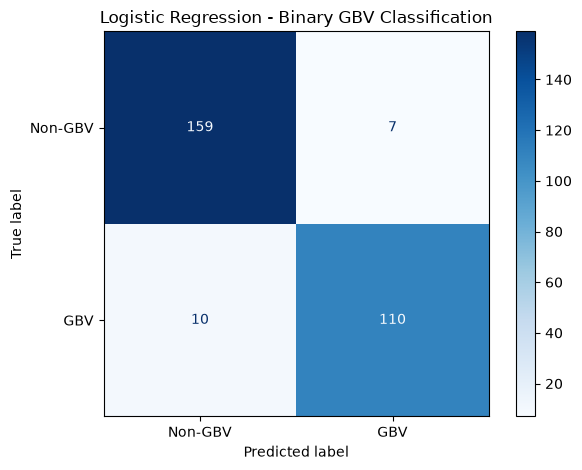

In [30]:
# Visualizing the confusion matrix
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_dev,
    y_dev_pred,
    display_labels=["Non-GBV", "GBV"],
    cmap="Blues",
    values_format="d"
)

plt.title("Logistic Regression - Binary GBV Classification")
plt.tight_layout()
plt.show()

DistilBERT achieved 97.20% development accuracy, compared with 94.06% for Logistic Regression. This suggests that DistilBERT performs better on the development dataset, although a final comparison using the same held-out test data and consistent preprocessing is still required.

# **Multi-label Logistic Regression**

In [31]:
# Creating the multilabel targets
# GBV categories
gbv_categories = [
    "domesticviolence",
    "rape",
    "sexualharassment",
    "childabuse_endangerment"
]

# Create multilabel targets
for category in gbv_categories:
    train_binary[category] = (
        train_binary["final_labels"]
        .str.contains(category, regex=False)
        .astype(int)
    )

    dev_binary[category] = (
        dev_binary["final_labels"]
        .str.contains(category, regex=False)
        .astype(int)
    )

# Separate multilabel targets
y_train_multi = train_binary[gbv_categories]
y_dev_multi = dev_binary[gbv_categories]

# Check category distributions
print("Training category counts:")
print(y_train_multi.sum())

print("\nDevelopment category counts:")
print(y_dev_multi.sum())

Training category counts:
domesticviolence           500
rape                       407
sexualharassment           373
childabuse_endangerment    182
dtype: int64

Development category counts:
domesticviolence           45
rape                       41
sexualharassment           33
childabuse_endangerment     8
dtype: int64


In [33]:
# Training the model
from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression

# Initialize multilabel Logistic Regression
lr_multilabel = OneVsRestClassifier(
    LogisticRegression(
        max_iter=1000,
        random_state=42
    )
)

# Train the model
lr_multilabel.fit(X_train_tfidf, y_train_multi)

# Predict on development data
y_dev_multi_pred = lr_multilabel.predict(X_dev_tfidf)


print("Prediction shape:", y_dev_multi_pred.shape)

Prediction shape: (286, 4)


In [34]:
# Evaluating the model
from sklearn.metrics import classification_report, f1_score

# Classification report for each GBV category
print("Multilabel Classification Report:\n")

print(
    classification_report(
        y_dev_multi,
        y_dev_multi_pred,
        target_names=gbv_categories,
        zero_division=0
    )
)

# Overall F1-scores
print(
    "Micro F1-score:",
    f1_score(y_dev_multi, y_dev_multi_pred, average="micro")
)

print(
    "Macro F1-score:",
    f1_score(y_dev_multi, y_dev_multi_pred, average="macro")
)

Multilabel Classification Report:

                         precision    recall  f1-score   support

       domesticviolence       1.00      0.47      0.64        45
                   rape       1.00      0.22      0.36        41
       sexualharassment       1.00      0.42      0.60        33
childabuse_endangerment       0.00      0.00      0.00         8

              micro avg       1.00      0.35      0.51       127
              macro avg       0.75      0.28      0.40       127
           weighted avg       0.94      0.35      0.50       127
            samples avg       0.15      0.15      0.15       127

Micro F1-score: 0.5146198830409356
Macro F1-score: 0.39802707930367504
